# Measure s of Dispersion / Variability(spread)

while central tendency gives us the center of dataset , measure of disoersion describe how spread out or clustered 

# 1. Range(Spread from minimum to maximum)

In [2]:
import numpy as np
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid')

12
12
12


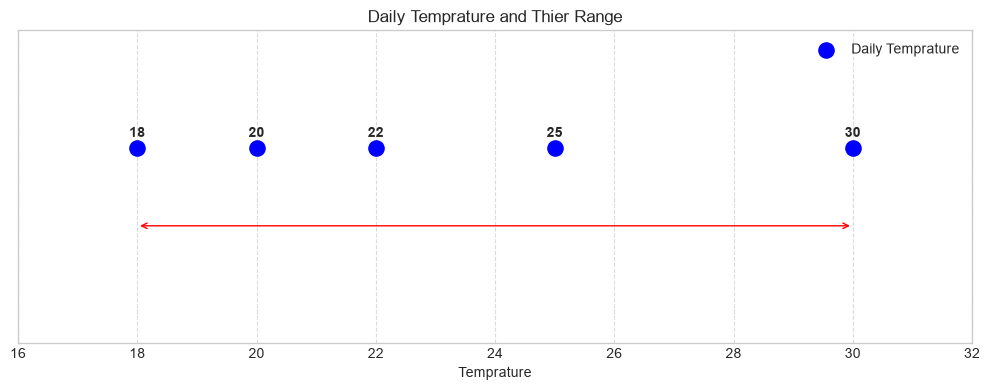

In [4]:
# Range Example 

temprature=[18,20,22,25,30]

min_val,max_val=min(temprature),max(temprature)

range_python=max(temprature)-min(temprature)

range_np_minmax=np.max(temprature)-np.min(temprature)

range_np_ptp=np.ptp(temprature)

print(range_python)
print(range_np_minmax)
print(range_np_ptp)


#visualization

plt.figure(figsize=(10,4))

plt.scatter(temprature, 
            [1]*len(temprature),
            color='blue',
            s=120,
            zorder=2,
            label="Daily Temprature")

#for each point Annotation

for i,temp in enumerate(temprature):
    plt.text(temp,1.02,f"{temp}",ha='center',va='bottom',fontsize=10,fontweight='bold')

plt.annotate("",xy=(min_val,0.8),xytext=(max_val,0.8),arrowprops=dict(arrowstyle="<->",color='red'))
plt.ylim(0.5,1.3)
plt.xlim(min(temprature)-2,max(temprature)+2)
plt.yticks([])
plt.xlabel("Temprature")
plt.title("Daily Temprature and Thier Range")
plt.grid(True,linestyle='--',alpha=0.7,axis='x')
plt.legend()
plt.tight_layout()
plt.show()


# 2. Interquartile Range (IQR - Middle 50% Spread)

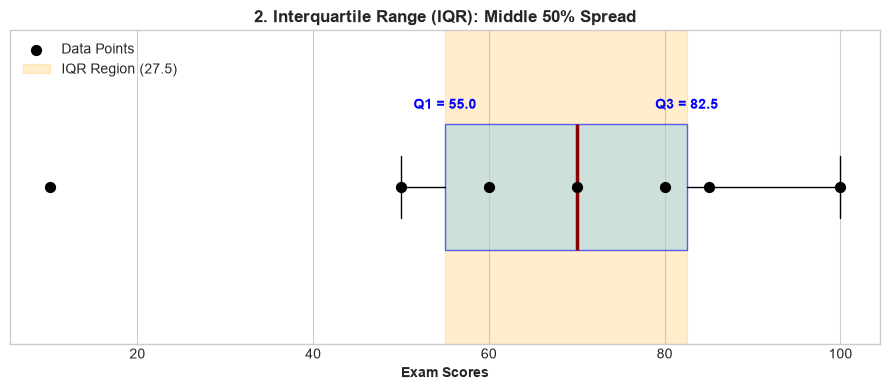

In [3]:
scores = [10, 50, 60, 70, 80, 85, 100]
q1 = np.percentile(scores, 25, method='linear')
q3 = np.percentile(scores, 75, method='linear')
iqr = q3 - q1

fig, ax = plt.subplots(figsize=(9, 4))

# Plot horizontal boxplot
bp = ax.boxplot(scores, orientation='horizontal', patch_artist=True, widths=0.4,
                boxprops=dict(facecolor='lightblue', color='blue', alpha=0.6),
                medianprops=dict(color='darkred', linewidth=2.5))

# Plot raw points
ax.scatter(scores, [1] * len(scores), color='black', zorder=4, label='Data Points', s=50)

# Highlight IQR span
ax.axvspan(q1, q3, color='orange', alpha=0.2, label=f'IQR Region ({iqr:.1f})')

# Annotate Q1 and Q3
ax.text(q1, 1.25, f'Q1 = {q1:.1f}', ha='center', color='blue', fontweight='bold')
ax.text(q3, 1.25, f'Q3 = {q3:.1f}', ha='center', color='blue', fontweight='bold')

ax.set_yticks([])
ax.set_xlabel('Exam Scores', fontweight='bold')
ax.set_title('2. Interquartile Range (IQR): Middle 50% Spread', fontweight='bold')
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

# 3. Sample Variance (Average Sqaured Deviation)

In [6]:
# Sample Variance Example

import statistics 

plants=[10,20,30]

mean_val=sum(plants)/len(plants)

var_python=sum((x-mean_val)**2 for x in plants)/(len(plants)-1)

# Standard library (statistics)

var_stats=statistics.variance(plants)

# use numpy for variance

var_np=np.var(plants,ddof=1) # to make it sample variance we show ddof bessel's correction

print(var_python)
print(var_stats)
print(var_np)


100.0
100
100.0


# 4. Sample Standard Deviation 


In [5]:
# Sample Variance Example

import statistics 
import math

plants=[10,20,30]

mean_val=sum(plants)/len(plants)

var_val=sum((x-mean_val)**2 for x in plants)/len(plants)-1
std_python=math.sqrt(var_val)
# Standard library (statistics)

std_stats=statistics.stdev(plants)

# use numpy for variance

std_np=np.std(plants,ddof=1) # to make it sample variance we show ddof bessel's correction

print(std_python)
print(std_stats)
print(std_np)

8.103497187428813
10.0
10.0


In [6]:
# 4. Sample Standard Deviation Example
plants = [10, 20, 30]

# Plain Python
mean_val = sum(plants) / len(plants)
var_val = sum((x - mean_val) ** 2 for x in plants) / (len(plants) - 1)
std_python = math.sqrt(var_val)

# Standard Library (statistics)
std_stats = statistics.stdev(plants)

# NumPy Library (ddof=1 specifies sample standard deviation)
std_np = np.std(plants, ddof=1)

print(f"Plain Python calculation:  {std_python:.1f} cm")
print(f"statistics.stdev():        {std_stats:.1f} cm")
print(f"np.std(ddof=1):            {std_np:.1f} cm")

Plain Python calculation:  10.0 cm
statistics.stdev():        10.0 cm
np.std(ddof=1):            10.0 cm


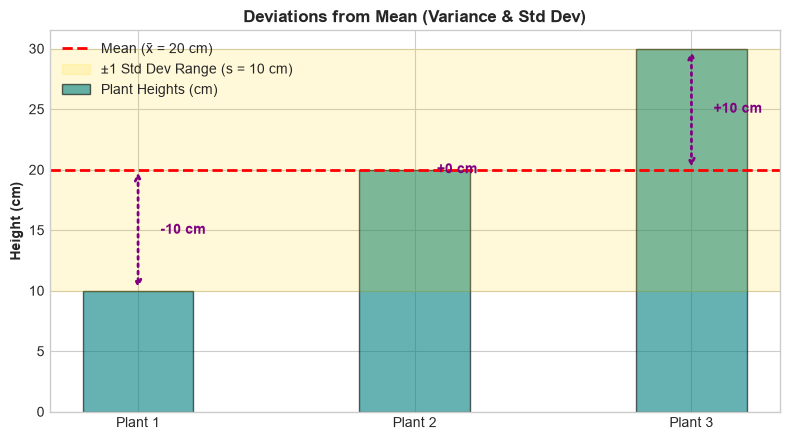

In [7]:
plants = [10, 20, 30]
mean_val = np.mean(plants)
std_val = np.std(plants, ddof=1)

fig, ax = plt.subplots(figsize=(8, 4.5))
x_indices = np.arange(1, len(plants) + 1)
bars = ax.bar(x_indices, plants, width=0.4, color='teal', alpha=0.6, label='Plant Heights (cm)', edgecolor='black')

# Draw Mean Line
ax.axhline(mean_val, color='red', linestyle='--', linewidth=2, label=f'Mean (x̄ = {mean_val:.0f} cm)')

# Draw deviation vectors
for idx, h in zip(x_indices, plants):
    ax.annotate('', xy=(idx, h), xytext=(idx, mean_val),
                arrowprops=dict(arrowstyle='<->', color='purple', lw=2, linestyle=':'))
    dev = h - mean_val
    ax.text(idx + 0.08, (h + mean_val) / 2, f'{dev:+0.0f} cm', color='purple', fontweight='bold', va='center')


# Highlight ±1 Std Dev Band
ax.axhspan(mean_val - std_val, mean_val + std_val, color='gold', alpha=0.15, label=f'±1 Std Dev Range (s = {std_val:.0f} cm)')

ax.set_xticks(x_indices)
ax.set_xticklabels([f'Plant {i}' for i in x_indices])
ax.set_ylabel('Height (cm)', fontweight='bold')
ax.set_title('Deviations from Mean (Variance & Std Dev)', fontweight='bold')
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()